✓ Downloaded 4004 days of data
Engineering features...
Dropping NaN values...
✓ Removed 199 rows with NaN values

 Walk-Forward Validation Setup:
  Initial training size: 2663 samples
  Test window: 60 days
  Total data points: 3805

 Starting Walk-Forward Validation...

  Window 1: Train[0:2663] → Test[2663:2723]

  Window 2: Train[0:2723] → Test[2723:2783]

  Window 3: Train[0:2783] → Test[2783:2843]

  Window 4: Train[0:2843] → Test[2843:2903]

  Window 5: Train[0:2903] → Test[2903:2963]

  Window 6: Train[0:2963] → Test[2963:3023]

  Window 7: Train[0:3023] → Test[3023:3083]

  Window 8: Train[0:3083] → Test[3083:3143]

  Window 9: Train[0:3143] → Test[3143:3203]

  Window 10: Train[0:3203] → Test[3203:3263]

  Window 11: Train[0:3263] → Test[3263:3323]

  Window 12: Train[0:3323] → Test[3323:3383]

  Window 13: Train[0:3383] → Test[3383:3443]

  Window 14: Train[0:3443] → Test[3443:3503]

  Window 15: Train[0:3503] → Test[3503:3563]

  Window 16: Train[0:3563] → Test[3563:3623]

 

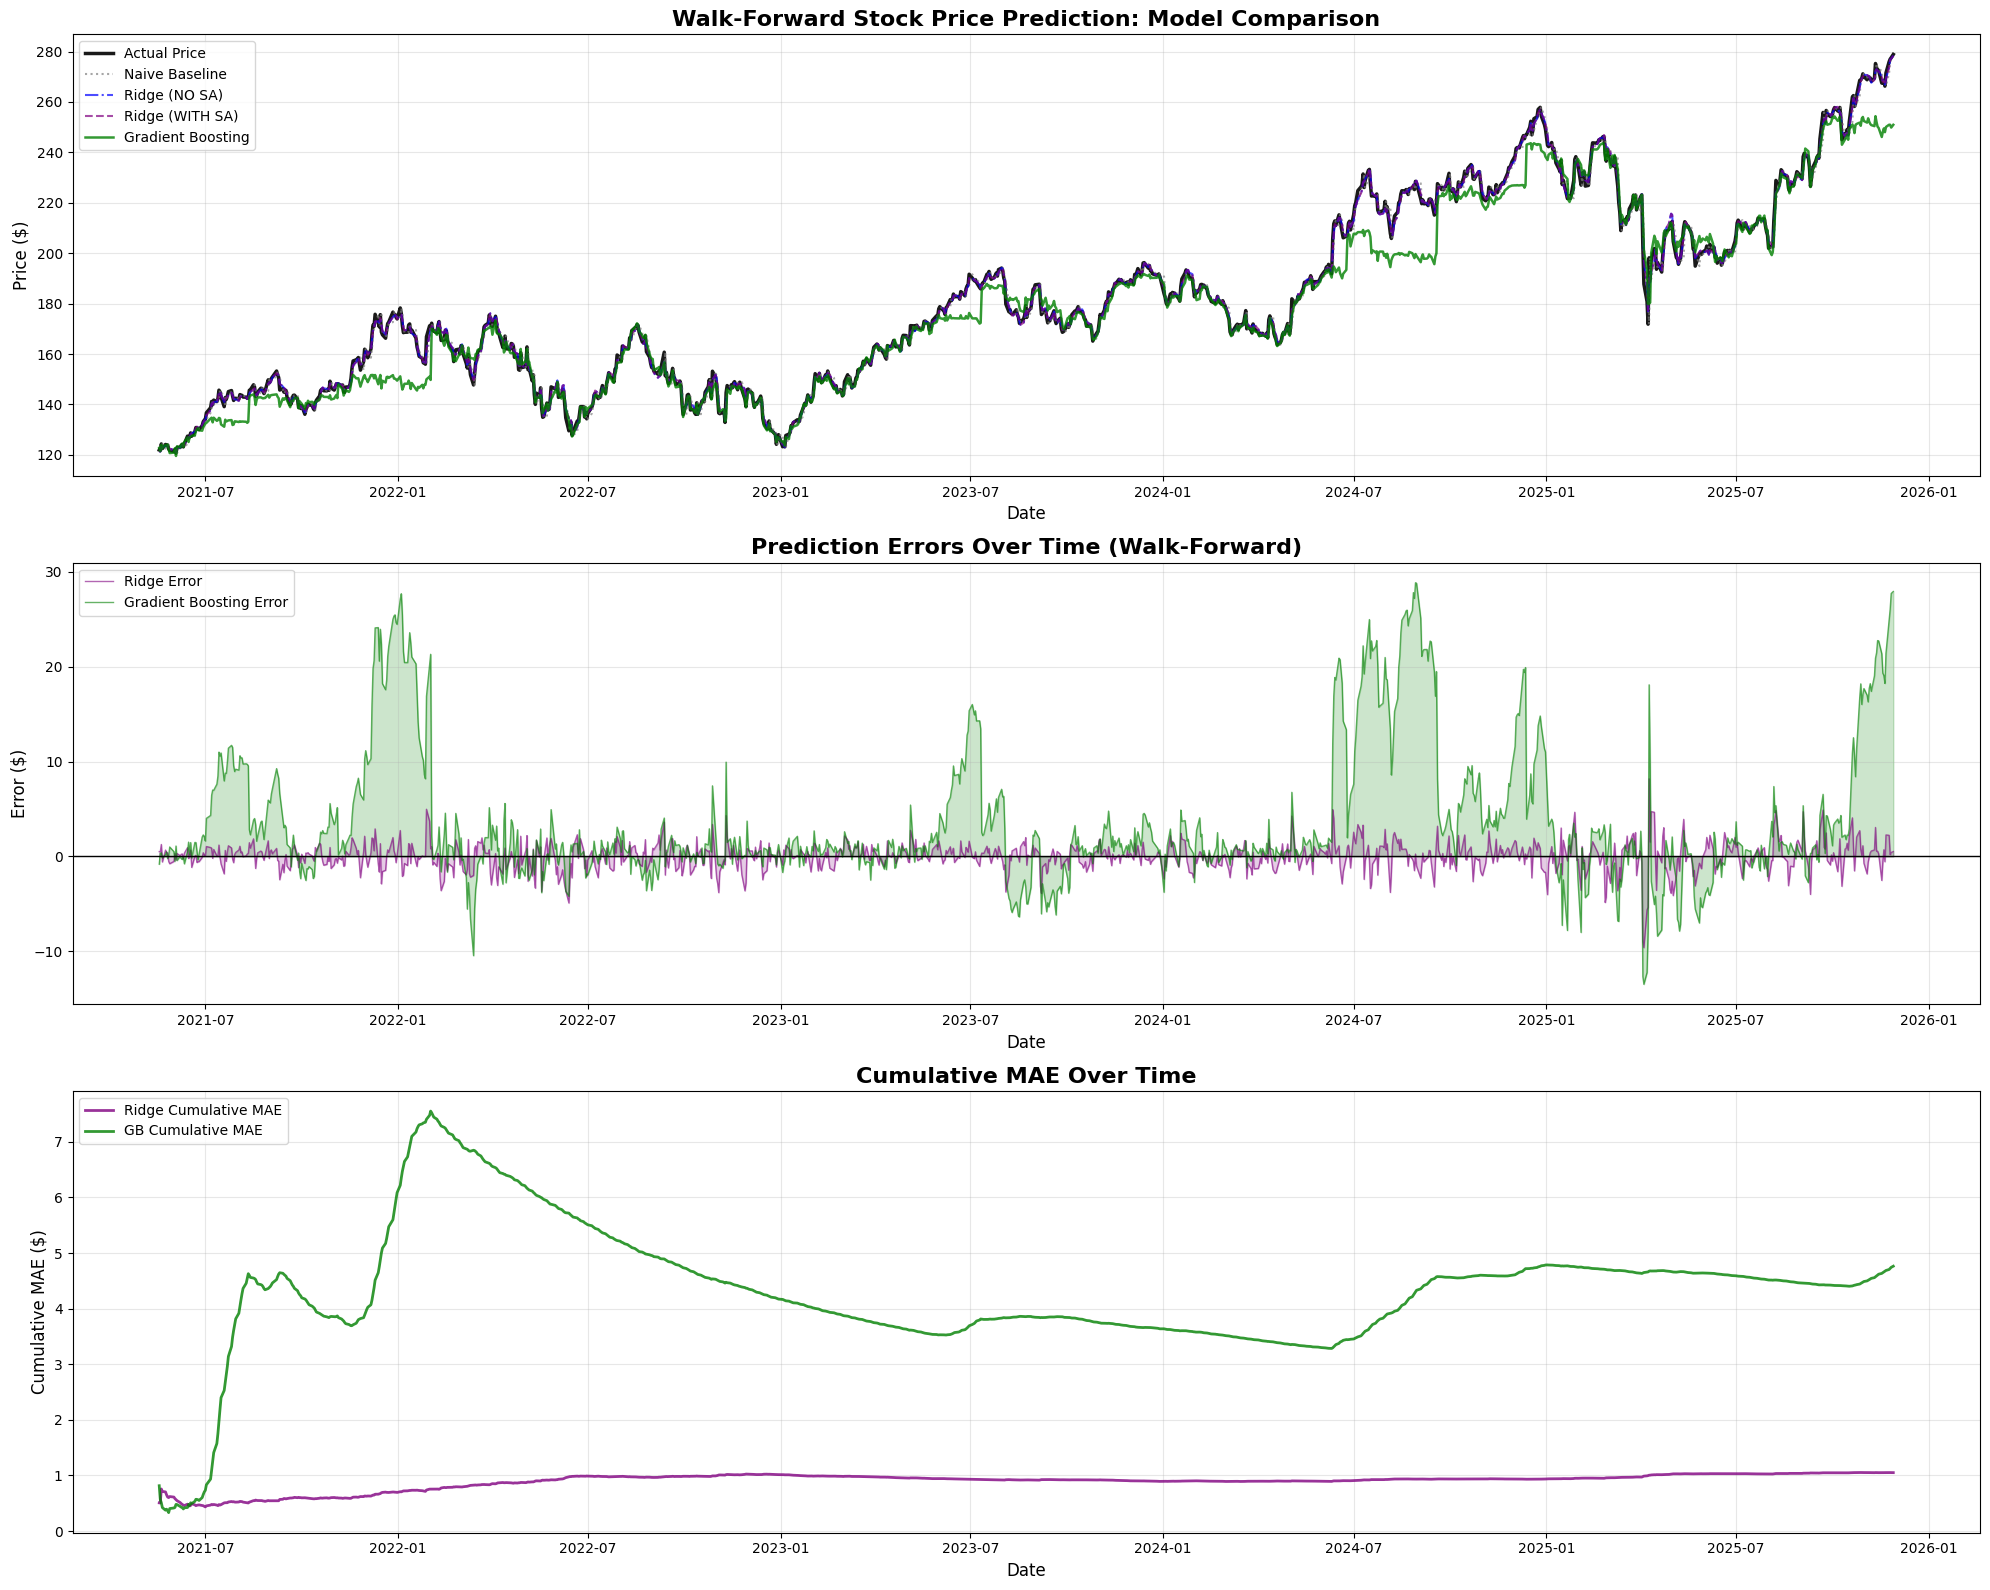


 Walk-Forward Analysis Complete!


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# --- HELPER FUNCTIONS ---
def calculate_rsi(prices, period=14):
    """Calculate Relative Strength Index"""
    delta = prices.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

def calculate_macd(prices, fast=12, slow=26, signal=9):
    """Calculate MACD and Signal Line"""
    ema_fast = prices.ewm(span=fast, adjust=False).mean()
    ema_slow = prices.ewm(span=slow, adjust=False).mean()
    macd = ema_fast - ema_slow
    macd_signal = macd.ewm(span=signal, adjust=False).mean()
    return macd, macd_signal

def calculate_atr(high, low, close, period=14):
    """Calculate Average True Range"""
    high_low = high - low
    high_close = np.abs(high - close.shift())
    low_close = np.abs(low - close.shift())
    ranges = pd.concat([high_low, high_close, low_close], axis=1)
    true_range = np.max(ranges, axis=1)
    atr = true_range.rolling(window=period).mean()
    return atr

def calculate_bollinger_bands(prices, period=20, std_dev=2):
    """Calculate Bollinger Bands"""
    sma = prices.rolling(window=period).mean()
    std = prices.rolling(window=period).std()
    upper_band = sma + (std * std_dev)
    lower_band = sma - (std * std_dev)
    return upper_band, lower_band

def engineer_features(df):
    """
    Engineer all features for a dataframe
    This function is called separately for each walk-forward window
    to prevent data leakage
    """
    data = df.copy()

    # 1. Lagged Price Features (no data leakage)
    for lag in [1, 2, 3, 5, 10, 20, 60]:
        data[f"Close_lag{lag}"] = data["Close"].shift(lag)

    data["Open_lag1"] = data["Open"].shift(1)
    data["High_lag1"] = data["High"].shift(1)
    data["Low_lag1"] = data["Low"].shift(1)
    data["Volume_lag1"] = data["Volume"].shift(1)

    # 2. Moving Averages and Crossovers (Simple and Exponential)
    data['SMA_10'] = data['Close'].rolling(window=10).mean()
    data['SMA_20'] = data['Close'].rolling(window=20).mean()
    data['SMA_50'] = data['Close'].rolling(window=50).mean()
    data['SMA_200'] = data['Close'].rolling(window=200).mean()
    data['EMA_12'] = data['Close'].ewm(span=12, adjust=False).mean()#ewm stands for exponential weighted mean 
    data['EMA_26'] = data['Close'].ewm(span=26, adjust=False).mean()

    # Price relative to moving averages
    data['Price_to_SMA20'] = data['Close'] / data['SMA_20']
    data['Price_to_SMA50'] = data['Close'] / data['SMA_50']

    # 3. Momentum and Trend Indicators
    data['RSI'] = calculate_rsi(data['Close'])
    data['MACD'], data['MACD_Signal'] = calculate_macd(data['Close'])
    data['MACD_Histogram'] = data['MACD'] - data['MACD_Signal']

    # Rate of Change
    data['ROC_5'] = data['Close'].pct_change(periods=5) * 100
    data['ROC_20'] = data['Close'].pct_change(periods=20) * 100

    # 4. Volatility Indicators
    data['ATR'] = calculate_atr(data['High'], data['Low'], data['Close'])
    data['BB_Upper'], data['BB_Lower'] = calculate_bollinger_bands(data['Close'])
    data['BB_Width'] = (data['BB_Upper'] - data['BB_Lower']) / data['SMA_20']
    data['Volatility_20'] = data['Close'].rolling(window=20).std()

    # 5. Volume Features
    data['Volume_SMA_20'] = data['Volume'].rolling(window=20).mean()
    data['Volume_Ratio'] = data['Volume'] / data['Volume_SMA_20']

    # 6. Price Action Features
    data['Daily_Return'] = data['Close'].pct_change()
    data['High_Low_Spread'] = (data['High'] - data['Low']) / data['Close']
    data['Close_Open_Spread'] = (data['Close'] - data['Open']) / data['Open']

    # 7. Synthetic Sentiment Feature (deterministic for reproducibility)
    np.random.seed(42)
    sentiment_base = np.random.normal(loc=0.1, scale=0.5, size=len(data))
    data['Sentiment_Score'] = sentiment_base
    data['Sentiment_Momentum'] = data['Daily_Return'].rolling(window=5).mean()

    return data

def evaluate_model(y_true, y_pred, model_name):
    """Calculates comprehensive performance metrics"""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    return {
        'Model': model_name,
        'MAE ($)': round(mae, 4),
        'RMSE ($)': round(rmse, 4),
        'R² Score': round(r2, 4),
        'MAPE (%)': round(mape, 2)
    }


# 1. DATA ACQUISITION


print("Downloading Apple stock data...")
raw_data = yf.Ticker("AAPL").history(start="2010-01-01")
print(f"✓ Downloaded {len(raw_data)} days of data")

# Engineer features on the full dataset
print("Engineering features...")
data = engineer_features(raw_data)

# Drop NaN values
print(f"Dropping NaN values...")
initial_len = len(data)
data = data.dropna()
print(f"✓ Removed {initial_len - len(data)} rows with NaN values")


# 2. FEATURE SELECTION AND WALK-FORWARD SETUP


# Feature Sets
base_features = [
    "Close_lag1", "Close_lag2", "Close_lag3", "Close_lag5", "Close_lag10",
    "Close_lag20", "Close_lag60",
    "Open_lag1", "High_lag1", "Low_lag1", "Volume_lag1",
    "SMA_10", "SMA_20", "SMA_50", "SMA_200",
    "EMA_12", "EMA_26",
    "Price_to_SMA20", "Price_to_SMA50",
    "RSI", "MACD", "MACD_Signal", "MACD_Histogram",
    "ROC_5", "ROC_20",
    "ATR", "BB_Width", "Volatility_20",
    "Volume_Ratio", "Daily_Return",
    "High_Low_Spread", "Close_Open_Spread"
]

sentiment_features = ["Sentiment_Score", "Sentiment_Momentum"]

# Walk-forward parameters
initial_train_size = int(len(data) * 0.70)  # Initial 70% for training
test_window = 60  # Test on 60 days at a time
min_train_size = 500  # Minimum training samples

print(f"\n Walk-Forward Validation Setup:")
print(f"  Initial training size: {initial_train_size} samples")
print(f"  Test window: {test_window} days")
print(f"  Total data points: {len(data)}")


# 3. WALK-FORWARD VALIDATION WITH PROPER SCALING


print("\n Starting Walk-Forward Validation...")

# Storage for predictions across all windows
all_predictions = {
    'Naive': [],
    'Ridge_NO_SA': [],
    'Ridge_WITH_SA': [],
    'Lasso_NO_SA': [],
    'ElasticNet': [],
    'RandomForest': [],
    'GradientBoosting': []
}
all_actuals = []
all_dates = []

# Hyperparameters (pre-tuned for speed, or you can tune in first window)
best_ridge_alpha = 1.0
best_lasso_alpha = 0.1

# Walk-forward loop
train_start = 0
train_end = initial_train_size

window_num = 0
while train_end + test_window <= len(data):
    window_num += 1
    test_start = train_end
    test_end = test_start + test_window

    print(f"\n  Window {window_num}: Train[{train_start}:{train_end}] → Test[{test_start}:{test_end}]")

    # === PREPARE DATA FOR THIS WINDOW ===
    # Extract train and test WITHOUT re-engineering features (already done)
    train_data = data.iloc[train_start:train_end]
    test_data = data.iloc[test_start:test_end]

    # Separate features and target
    X_train_no_sa = train_data[base_features]
    X_train_sa = train_data[base_features + sentiment_features]
    y_train = train_data["Close"]

    X_test_no_sa = test_data[base_features]
    X_test_sa = test_data[base_features + sentiment_features]
    y_test = test_data["Close"]

    # === SCALE DATA (fit on train, transform train AND test) ===
    scaler_no_sa = StandardScaler()
    X_train_scaled_no_sa = scaler_no_sa.fit_transform(X_train_no_sa)
    X_test_scaled_no_sa = scaler_no_sa.transform(X_test_no_sa)

    scaler_sa = StandardScaler()
    X_train_scaled_sa = scaler_sa.fit_transform(X_train_sa)
    X_test_scaled_sa = scaler_sa.transform(X_test_sa)

    #  TRAIN MODELS ON THIS WINDOW

    # 1. Naive Baseline
    naive_pred = X_test_no_sa["Close_lag1"].values

    # 2. Ridge (NO SA)
    ridge_no_sa = Ridge(alpha=best_ridge_alpha, random_state=42)
    ridge_no_sa.fit(X_train_scaled_no_sa, y_train)
    ridge_pred_no_sa = ridge_no_sa.predict(X_test_scaled_no_sa)

    # 3. Ridge (WITH SA)
    ridge_sa = Ridge(alpha=best_ridge_alpha, random_state=42)
    ridge_sa.fit(X_train_scaled_sa, y_train)
    ridge_pred_sa = ridge_sa.predict(X_test_scaled_sa)

    # 4. Lasso (NO SA)
    lasso_no_sa = Lasso(alpha=best_lasso_alpha, max_iter=10000, random_state=42)
    lasso_no_sa.fit(X_train_scaled_no_sa, y_train)
    lasso_pred_no_sa = lasso_no_sa.predict(X_test_scaled_no_sa)

    # 5. ElasticNet
    elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000, random_state=42)
    elastic_net.fit(X_train_scaled_sa, y_train)
    elastic_pred = elastic_net.predict(X_test_scaled_sa)

    # 6. Random Forest
    rf = RandomForestRegressor(
        n_estimators=100,  # Reduced for speed in walk-forward
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train_sa, y_train)
    rf_pred = rf.predict(X_test_sa)

    # 7. Gradient Boosting
    gb = GradientBoostingRegressor(
        n_estimators=100,  # Reduced for speed
        learning_rate=0.05,
        max_depth=5,
        min_samples_split=10,
        random_state=42
    )
    gb.fit(X_train_sa, y_train)
    gb_pred = gb.predict(X_test_sa)

    #  STORE PREDICTIONS
    all_predictions['Naive'].extend(naive_pred)
    all_predictions['Ridge_NO_SA'].extend(ridge_pred_no_sa)
    all_predictions['Ridge_WITH_SA'].extend(ridge_pred_sa)
    all_predictions['Lasso_NO_SA'].extend(lasso_pred_no_sa)
    all_predictions['ElasticNet'].extend(elastic_pred)
    all_predictions['RandomForest'].extend(rf_pred)
    all_predictions['GradientBoosting'].extend(gb_pred)

    all_actuals.extend(y_test.values)
    all_dates.extend(y_test.index)

    # Move window forward (expanding window - keeps all historical data)
    train_end = test_end

print(f"\n Completed {window_num} walk-forward windows")


# 4. AGGREGATE RESULTS AND EVALUATION


# Convert to arrays for evaluation
all_actuals = np.array(all_actuals)
all_dates = pd.DatetimeIndex(all_dates)

results_list = []
for model_name, predictions in all_predictions.items():
    predictions = np.array(predictions)
    results_list.append(evaluate_model(all_actuals, predictions, model_name))

results_df = pd.DataFrame(results_list)
results_df = results_df.sort_values('MAE ($)')

print("\n" + "="*80)
print("WALK-FORWARD MODEL PERFORMANCE (Aggregated Test Results)")
print("="*80)
print(results_df.to_string(index=False))
print("="*80)

# Find best model
best_model = results_df.iloc[0]['Model']
print(f"\n Best Model: {best_model}")
print(f"   MAE: ${results_df.iloc[0]['MAE ($)']}")
print(f"   RMSE: ${results_df.iloc[0]['RMSE ($)']}")
print(f"   R² Score: {results_df.iloc[0]['R² Score']}")


# 5. ENHANCED VISUALIZATION


fig, axes = plt.subplots(3, 1, figsize=(20, 16))

# Plot 1: Main Comparison
ax1 = axes[0]
ax1.plot(all_dates, all_actuals, label="Actual Price", color='black', linewidth=2.5, alpha=0.9)
ax1.plot(all_dates, all_predictions['Naive'], label="Naive Baseline",
         color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax1.plot(all_dates, all_predictions['Ridge_NO_SA'], label="Ridge (NO SA)",
         color='blue', linestyle='-.', linewidth=1.5, alpha=0.7)
ax1.plot(all_dates, all_predictions['Ridge_WITH_SA'], label="Ridge (WITH SA)",
         color='purple', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.plot(all_dates, all_predictions['GradientBoosting'], label="Gradient Boosting",
         color='green', linestyle='-', linewidth=1.8, alpha=0.8)

ax1.set_title("Walk-Forward Stock Price Prediction: Model Comparison",
              fontsize=16, fontweight='bold')
ax1.set_xlabel("Date", fontsize=12)
ax1.set_ylabel("Price ($)", fontsize=12)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot 2: Prediction Error Analysis
ax2 = axes[1]
errors_ridge = all_actuals - all_predictions['Ridge_WITH_SA']
errors_gb = all_actuals - all_predictions['GradientBoosting']

ax2.plot(all_dates, errors_ridge, label="Ridge Error", color='purple', alpha=0.6, linewidth=1)
ax2.plot(all_dates, errors_gb, label="Gradient Boosting Error", color='green', alpha=0.6, linewidth=1)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax2.fill_between(all_dates, 0, errors_ridge, alpha=0.2, color='purple')
ax2.fill_between(all_dates, 0, errors_gb, alpha=0.2, color='green')

ax2.set_title("Prediction Errors Over Time (Walk-Forward)", fontsize=16, fontweight='bold')
ax2.set_xlabel("Date", fontsize=12)
ax2.set_ylabel("Error ($)", fontsize=12)
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)

# Plot 3: Cumulative MAE over time
ax3 = axes[2]
cumulative_mae_ridge = []
cumulative_mae_gb = []
for i in range(1, len(all_actuals) + 1):
    cumulative_mae_ridge.append(mean_absolute_error(all_actuals[:i], all_predictions['Ridge_WITH_SA'][:i]))
    cumulative_mae_gb.append(mean_absolute_error(all_actuals[:i], all_predictions['GradientBoosting'][:i]))

ax3.plot(all_dates, cumulative_mae_ridge, label="Ridge Cumulative MAE",
         color='purple', linewidth=2, alpha=0.8)
ax3.plot(all_dates, cumulative_mae_gb, label="GB Cumulative MAE",
         color='green', linewidth=2, alpha=0.8)

ax3.set_title("Cumulative MAE Over Time", fontsize=16, fontweight='bold')
ax3.set_xlabel("Date", fontsize=12)
ax3.set_ylabel("Cumulative MAE ($)", fontsize=12)
ax3.legend(loc='upper left', fontsize=10)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n Walk-Forward Analysis Complete!")
